# Week 7 – Dimensionality Reduction
Renewable Energy & Weather Dataset

Course: 24ADI204 – Data Science and Visualization

Participants:

25BAD063 – K.S. Nagul Nisok

25BAD067 – V. Nidhish

25BAD068 – B. Nirmal

25BAD073 – S. Nivesh

**Aim:** Perform feature selection and Principal Component Analysis (PCA), and visualize explained variance using the cleaned dataset.



## Step 1: Import libraries

In [ ]:
from pathlib import Path
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
sns.set_theme(style="whitegrid")

## Step 2: Load the cleaned dataset

In [ ]:
csv_path = Path("NewsData_Renewable_Energy_Final.csv")
if csv_path.exists():
    df = pd.read_csv(csv_path)
else:
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[filename]))
print("Dataset shape:", df.shape)
display(df[["article_id", "Year", "Title_Length", "Description_Length", "Content_Length", "Keyword_Count"]].head())

Saving NewsData_Renewable_Energy_Final.csv to NewsData_Renewable_Energy_Final.csv
Dataset shape: (3754, 25)


,article_id,Year,Title_Length,Description_Length,Content_Length,Keyword_Count
0,34fa2a78349418b971cbce5686908804,2024,53,1672,1672,1
1,9a28fd4fd309b17db653ea86e4c7b8c1,2024,82,468,4730,1
2,81bdbec184bb3cfa549c1d75dd1ef4a9,2024,46,567,2351,1
3,e9c00bb7e42f0ee78d40221608feb878,2024,84,159,1990,1
4,d0acebec6222d82a927acae52d3664a3,2024,160,356,5167,3


## Step 3: Select existing numerical features
Use the six numerical columns already present in the cleaned dataset. Article IDs, URLs and raw text are excluded because they are not continuous measurements. Sentiment is used only to color the final plot.

Validate the input without performing additional cleaning or feature engineering.

In [ ]:
feature_columns = ["source_priority", "Year", "Title_Length", "Description_Length", "Content_Length", "Keyword_Count"]
X = df[feature_columns].copy()
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("The numerical input contains missing or infinite values. Please check the cleaned CSV.")
print("Numerical features:", feature_columns)
display(X.describe().round(2))

Numerical features: ['source_priority', 'Year', 'Title_Length', 'Description_Length', 'Content_Length', 'Keyword_Count']


,source_priority,Year,Title_Length,Description_Length,Content_Length,Keyword_Count
count,3.754000e+03,3754.00,3754.00,3754.00,3754.00,3754.00
mean,3.218495e+06,2023.91,75.82,1539.18,3071.19,12.04
std,3.303692e+07,0.28,26.60,2889.91,4193.07,67.95
min,1.400000e+01,2023.00,10.00,7.00,1.00,1.00
25%,1.336100e+04,2024.00,58.00,198.00,167.00,1.00
50%,1.677790e+05,2024.00,72.00,337.00,2126.50,1.00
75%,4.587220e+05,2024.00,90.00,1088.25,4266.00,3.00
max,7.483337e+08,2024.00,249.00,35830.00,79765.00,1068.00


## Step 4: Variance thresholding
Remove constant columns using a variance threshold of zero. A constant feature provides no information for distinguishing articles. This threshold is not affected by the units of measurement.

In [ ]:
selector = VarianceThreshold(threshold=0.0)
selector.fit(X)
display(pd.DataFrame({"Feature": X.columns, "Variance": selector.variances_, "Retained": selector.get_support()}))
X_var = X.loc[:, selector.get_support()].copy()
print("Constant features removed:", X.columns[~selector.get_support()].tolist())

,Feature,Variance,Retained
0,source_priority,7.483337e+08,True
1,Year,7.907921e-02,True
2,Title_Length,2.390000e+02,True
3,Description_Length,3.582300e+04,True
4,Content_Length,7.976400e+04,True
5,Keyword_Count,1.067000e+03,True


Constant features removed: []


## Step 5: Correlation-based feature selection
Remove a feature if its absolute Pearson correlation with an already retained feature is greater than 0.90. This limits multicollinearity. The column order determines which feature is kept from a highly correlated pair. If no pair exceeds the threshold, keep all nonconstant features.

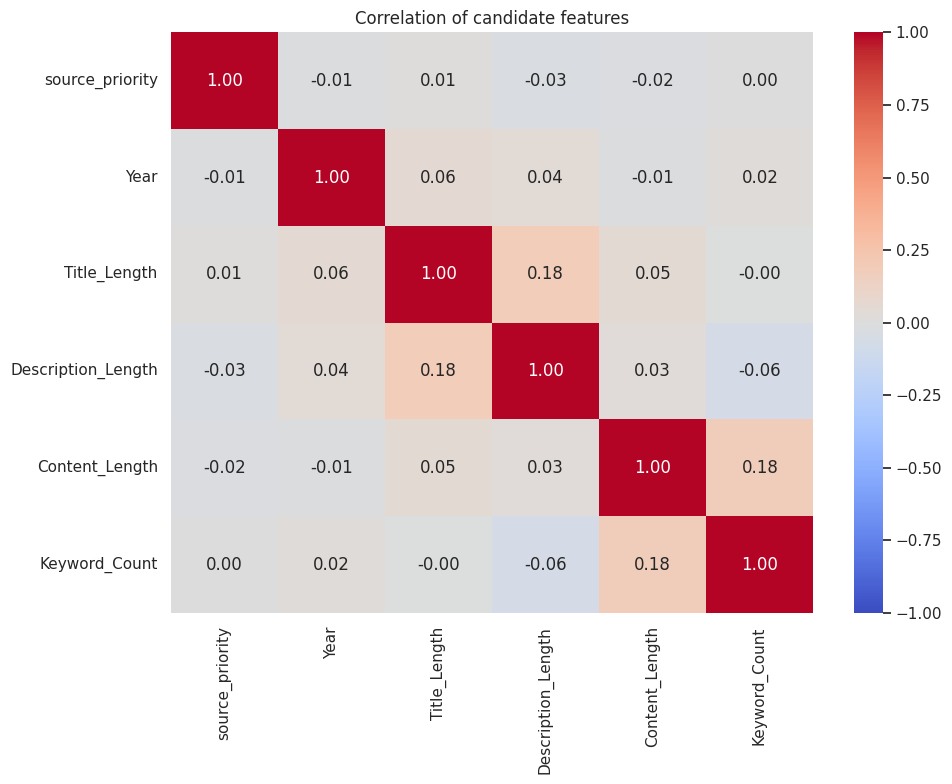

Correlated features removed: []
Selected features: ['source_priority', 'Year', 'Title_Length', 'Description_Length', 'Content_Length', 'Keyword_Count']
Feature counts: 6 → 6 → 6


In [ ]:
corr = X_var.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation of candidate features")
plt.tight_layout()
plt.show()
selected, removed = [], []
for column in X_var.columns:
    if any(abs(corr.loc[column, kept]) > 0.90 for kept in selected):
        removed.append(column)
    else:
        selected.append(column)
X_selected = X_var[selected]
print("Correlated features removed:", removed)
print("Selected features:", selected)
print("Feature counts:", X.shape[1], "→", X_var.shape[1], "→", X_selected.shape[1])

## Step 6: Standardize features and apply PCA
Standardization is required for this PCA because source priority and text lengths have different numerical scales. PCA creates uncorrelated components from the standardized features. Fit all components first and determine the minimum number needed to retain at least 95% of variance.

This is exploratory analysis of the full dataset. For predictive modeling, fit scaling, selection and PCA on the training set only.

In [ ]:
if X_selected.shape[1] < 2:
    raise ValueError("At least two retained features are needed for the PCA plot.")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)
pca = PCA(svd_solver="full")
scores = pca.fit_transform(X_scaled)
ratio = pca.explained_variance_ratio_
cumulative = np.cumsum(ratio)
k = int(np.searchsorted(cumulative, 0.95) + 1)
variance = pd.DataFrame({"Component": [f"PC{i+1}" for i in range(len(ratio))], "Explained variance (%)": ratio * 100, "Cumulative variance (%)": cumulative * 100})
display(variance.round(2))
print("Components needed for at least 95% variance:", k)

,Component,Explained variance (%),Cumulative variance (%)
0,PC1,20.29,20.29
1,PC2,19.68,39.97
2,PC3,16.75,56.72
3,PC4,16.46,73.19
4,PC5,13.61,86.80
5,PC6,13.20,100.00


Components needed for at least 95% variance: 6


## Step 7: Visualize individual and cumulative explained variance

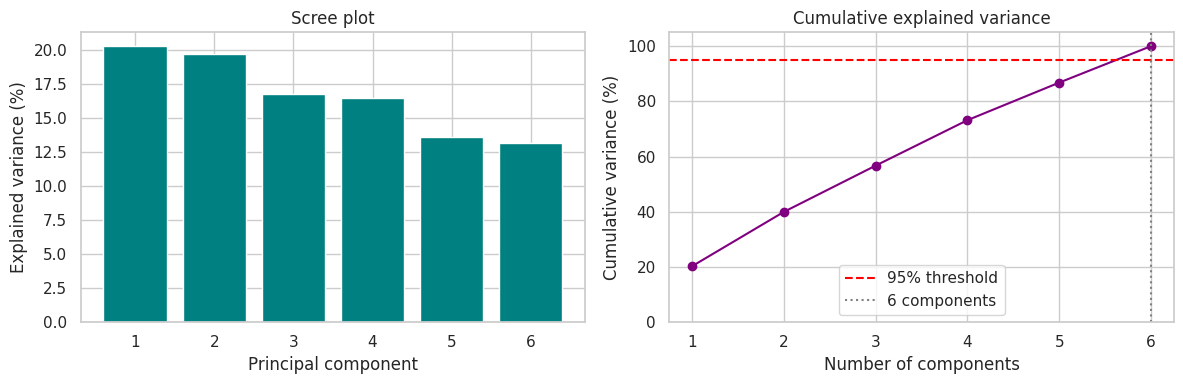

In [ ]:
component_numbers = np.arange(1, len(ratio) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(component_numbers, ratio * 100, color="teal")
axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="Explained variance (%)")
axes[1].plot(component_numbers, cumulative * 100, marker="o", color="purple")
axes[1].axhline(95, linestyle="--", color="red", label="95% threshold")
axes[1].axvline(k, linestyle=":", color="grey", label=f"{k} components")
axes[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Cumulative variance (%)", ylim=(0, 105))
for ax in axes:
    ax.set_xticks(component_numbers)
axes[1].legend()
plt.tight_layout()
plt.show()

## Step 8: Two-dimensional PCA visualization
Plot PC1 and PC2 and color the articles by their existing sentiment labels. Sentiment is not an input to PCA. The percentage printed below shows how much information the two-component view retains; it may be less than 95%.

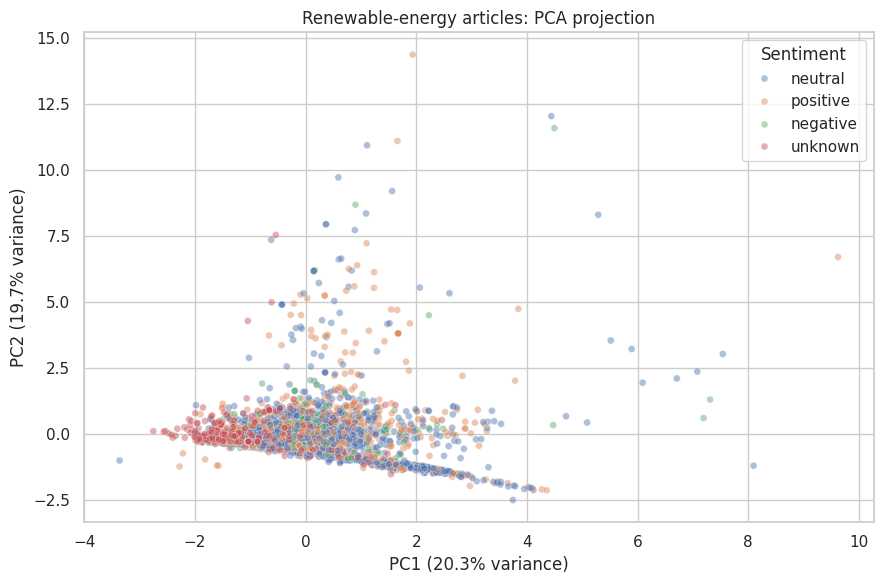

First two components retain 39.97% of the selected-feature variance.


In [ ]:
plot_data = pd.DataFrame(scores[:, :2], columns=["PC1", "PC2"])
plot_data["Sentiment"] = df["sentiment"].fillna("unknown").str.lower()
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_data, x="PC1", y="PC2", hue="Sentiment", alpha=0.45, s=25)
plt.xlabel(f"PC1 ({ratio[0]:.1%} variance)")
plt.ylabel(f"PC2 ({ratio[1]:.1%} variance)")
plt.title("Renewable-energy articles: PCA projection")
plt.tight_layout()
plt.show()
print(f"First two components retain {cumulative[1]:.2%} of the selected-feature variance.")

## Step 9: Interpret component weights
The coefficients show each feature's contribution to PC1 and PC2. Larger absolute values indicate stronger contributions. These are mathematical associations, not causal effects.

,PC1,PC2
source_priority,-0.083,-0.032
Year,0.284,-0.061
Title_Length,0.659,-0.083
Description_Length,0.627,-0.255
Content_Length,0.283,0.644
Keyword_Count,0.067,0.713


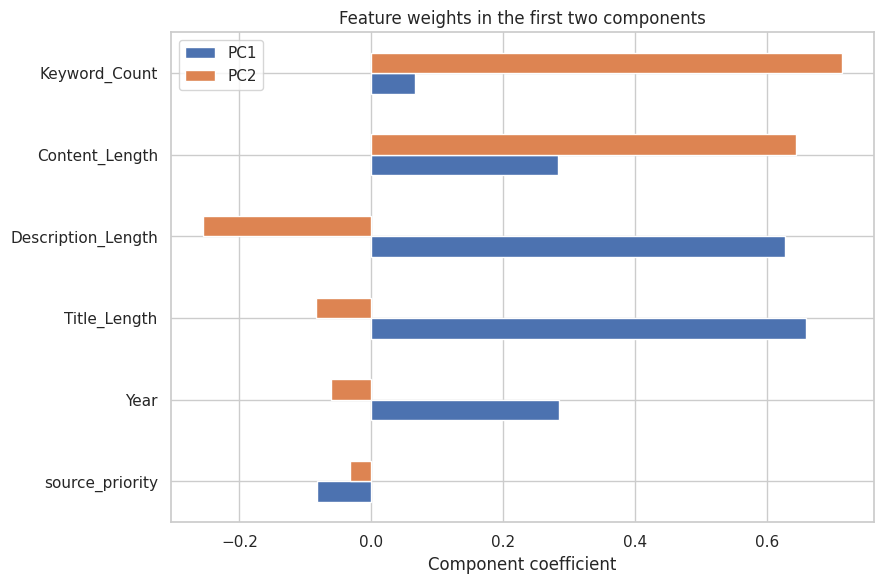

PC1 largest absolute weights: Title_Length, Description_Length, Year
PC2 largest absolute weights: Keyword_Count, Content_Length, Description_Length


In [ ]:
weights = pd.DataFrame(pca.components_[:2].T, index=X_selected.columns, columns=["PC1", "PC2"])
display(weights.round(3))
weights.plot.barh(figsize=(9, 6))
plt.title("Feature weights in the first two components")
plt.xlabel("Component coefficient")
plt.tight_layout()
plt.show()
for pc in weights.columns:
    top = weights[pc].abs().nlargest(3).index.tolist()
    print(pc, "largest absolute weights:", ", ".join(top))

## Step 10: Results and reduced dataset

In [ ]:
reduced = pd.DataFrame(scores[:, :k], columns=[f"PC{i+1}" for i in range(k)])
reduced.insert(0, "article_id", df["article_id"].to_numpy())
reduced["sentiment"] = df["sentiment"].to_numpy()
reduced.to_csv("Week7_PCA_Reduced_Data.csv", index=False)
variance.to_csv("Week7_Explained_Variance.csv", index=False)
print(f"Articles analyzed: {len(df):,}")
print(f"Original numerical features: {X.shape[1]}")
print(f"Features after selection: {len(selected)}")
print(f"Components for 95% variance: {k}")
print(f"Variance retained: {cumulative[k-1]:.2%}")
if k == len(selected):
    print("All selected dimensions are needed for the 95% target.")
else:
    print(f"PCA reduced {len(selected)} selected dimensions to {k} components.")
print("CSV outputs saved in the runtime folder.")
display(reduced.head())
assert np.isfinite(scores).all()
assert np.isclose(ratio.sum(), 1)
assert cumulative[k-1] >= 0.95 - 1e-12
assert "sentiment" not in X_selected.columns
print("Validation checks passed.")

Articles analyzed: 3,754
Original numerical features: 6
Features after selection: 6
Components for 95% variance: 6
Variance retained: 100.00%
All selected dimensions are needed for the 95% target.
CSV outputs saved in the runtime folder.


,article_id,PC1,PC2,PC3,PC4,PC5,PC6,sentiment
0,34fa2a78349418b971cbce5686908804,-0.547675,-0.287041,-0.249605,0.422790,-0.490347,0.338212,neutral
1,9a28fd4fd309b17db653ea86e4c7b8c1,0.116377,0.197779,-0.031242,0.245696,0.016628,-0.601396,neutral
2,81bdbec184bb3cfa549c1d75dd1ef4a9,-0.914538,-0.062964,-0.284598,0.512130,-0.572406,0.135553,neutral
3,e9c00bb7e42f0ee78d40221608feb878,-0.085037,-0.201286,-0.009238,0.381700,0.433042,-0.372809,positive
4,d0acebec6222d82a927acae52d3664a3,2.051380,0.048972,0.591084,-0.127089,1.831219,-1.619459,positive


Validation checks passed.


## Conclusion
Variance thresholding identifies constant numerical features, and correlation filtering checks for redundant features. PCA summarizes the selected standardized features. The scree plot and cumulative variance curve show how many components are required for the 95% target; the results above report the actual values.

The analysis describes news article lengths, keyword counts and source metadata. It does not measure renewable-energy generation or weather. Source priority is a supplied metadata value, not verified source quality. Large values may influence PCA even after standardization; the existing cleaned numerical values are used as supplied.